# $\texttt{bihalofit-JAX}$ tutorial

The nonlinear matter bispectrum of Takahashi et al. (2020) as a JAX function you can `jit`,
`vmap` and differentiate. The pattern never changes:

```python
bhf = make_bihalofit(k1, k2, k3, expfactors)   # once: fix the triangles and redshifts
B   = bhf(cosmo)                               # then: evaluate at any Cosmology
```

`B` has shape `(N_cosmo, N_z, N_tri)`. Units: $k$ in $h/\mathrm{Mpc}$, $B$ in $(\mathrm{Mpc}/h)^6$.
Source: `src/bispectrum.py`.

## The BiHaloFit formula

BiHaloFit (Takahashi et al. 2020, arXiv:1911.07886) models the nonlinear matter bispectrum as a sum of a **1-halo** and **3-halo** term:

$$B(k_1, k_2, k_3) = B^\mathrm{1h} + B^\mathrm{3h}$$

### 1-halo term

$$B^\mathrm{1h} = T(q_1)\, T(q_2)\, T(q_3)$$

where $q_i = k_i / k_\mathrm{NL}$ and

$$T(q) = \frac{c_n q}{(a_n q^{\alpha_n} + b_n q^{\beta_n})(1 + c_n q)}$$

The fitting coefficients $a_n, b_n, c_n, \alpha_n, \beta_n$ depend on $n_\mathrm{eff}$ and $\log_{10}\sigma_8(z)$.

### 3-halo term

$$B^\mathrm{3h} = 2\, I(q_1) I(q_2) I(q_3) \left[ \left(F_2(\mathbf{k}_1,\mathbf{k}_2) + d_n q_3\right) P_E(q_1) P_E(q_2) + \mathrm{cyc.} \right]$$

where $F_2$ is the standard SPT kernel, $P_E$ is an effective nonlinear power spectrum, and $I(q) = 1/(1 + e_n q)$.

### Key derived quantities

All fitting coefficients depend on three scale- and redshift-dependent quantities computed from the linear $P(k,z)$:

| Quantity | Definition | Role |
|---|---|---|
| $k_\mathrm{NL}$ | Scale where $\sigma^2(1/k_\mathrm{NL}) = 1$ | Sets the nonlinear scale |
| $n_\mathrm{eff}$ | $-3 + 2R^2 \int k^4 P \, e^{-k^2R^2} dk / (2\pi^2)$ at $R=1/k_\mathrm{NL}$ | Effective spectral index |
| $\sigma_8(z)$ | r.m.s. matter fluctuation in $8\,h^{-1}$Mpc spheres at redshift $z$ | Amplitude of fluctuations |
| $\Omega_m(z)$ | Matter density parameter at redshift $z$ | Appears in $e_n$, $d_n$ |

### Linear $P(k)$ backends

Four backends for the linear power spectrum, all differentiable:
- **`syren`** (default): syren-new (Sui et al. 2025), a symbolic-regression formula in JAX; neutrino mass and $w_0$/$w_a$
- **`baccoemu`**: the baccoemu neural-network emulator (optional dependency); neutrino mass and $w_0$/$w_a$
- **`eh`**: the Eisenstein & Hu 1998 no-wiggle formula in JAX
- **`eh_99`**: the Eisenstein & Hu 1999 formula at $f_\nu=0$, as used by `threepoint_py`

## 0. Setup

Imports `bihalofit_jax`, which must be installed.

In [1]:
import sys, os

# Allocate GPU memory as needed rather than reserving most of the card up front.
os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'
os.environ['TF_FORCE_GPU_ALLOW_GROWTH'] = 'true'

import bihalofit_jax    # pip install bihalofit-jax, or pip install -e . from a checkout

import numpy as np
import jax
from bihalofit_jax import make_bihalofit, Cosmology

print('bihalofit_jax:', bihalofit_jax.__file__)
print('JAX version:', jax.__version__)
print('JAX device: ', jax.devices())

bihalofit_jax: /tmp/bihalofit_jax_tutorials/lib/python3.12/site-packages/bihalofit_jax/__init__.py
JAX version: 0.12.0.1
JAX device:  [CpuDevice(id=0)]


## 1. Import the module

In [2]:
from bihalofit_jax import Cosmology
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Figure style: boxed axes with inward ticks on all four sides, no grid, no titles, 2-point lines,
# a colour-blind-safe cycle, one fixed colour per backend, and a single-hue blue ramp for ordered quantities.
plt.rcParams.update({
    'figure.figsize': (7.5, 4.8), 'figure.dpi': 110, 'figure.constrained_layout.use': True,
    'font.family': 'serif', 'mathtext.fontset': 'cm', 'font.size': 14, 'axes.labelsize': 16,
    'axes.linewidth': 0.8, 'axes.grid': False, 'xtick.labelsize': 13, 'ytick.labelsize': 13,
    'xtick.major.size': 5, 'ytick.major.size': 5, 'xtick.minor.size': 2.5, 'ytick.minor.size': 2.5,
    'xtick.direction': 'in', 'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True,
    'xtick.minor.visible': True, 'ytick.minor.visible': True,
    'lines.linewidth': 2, 'lines.solid_capstyle': 'round', 'legend.frameon': False, 'legend.fontsize': 13,
    'axes.prop_cycle': plt.cycler(color=['#2a78d6', '#eb6834', '#1baf7a', '#eda100']),
})
BLUES  = LinearSegmentedColormap.from_list('blues', ['#86b6ef', '#184f95'])
COLOUR = {'baccoemu': '#2a78d6', 'syren': '#eb6834', 'eh': '#1baf7a', 'eh_99': '#eda100'}

# baccoemu loads on first call (slow, ~5 s); subsequent calls reuse the cached instance
print('Import OK')

Import OK


## 2. Build once, call with a cosmology

`make_bihalofit` does all the NumPy setup and JIT compilation for a fixed set of triangles and
redshifts and returns a function of a `Cosmology`. Build it once; later calls reuse the compiled
kernel. The linear power spectrum comes from `pk_source` (default `'syren'`; see section 5).

Here: the Planck 2015 fiducial cosmology (reused throughout) and every valid triangle on a
log-spaced $k$ grid, at $z=0$.

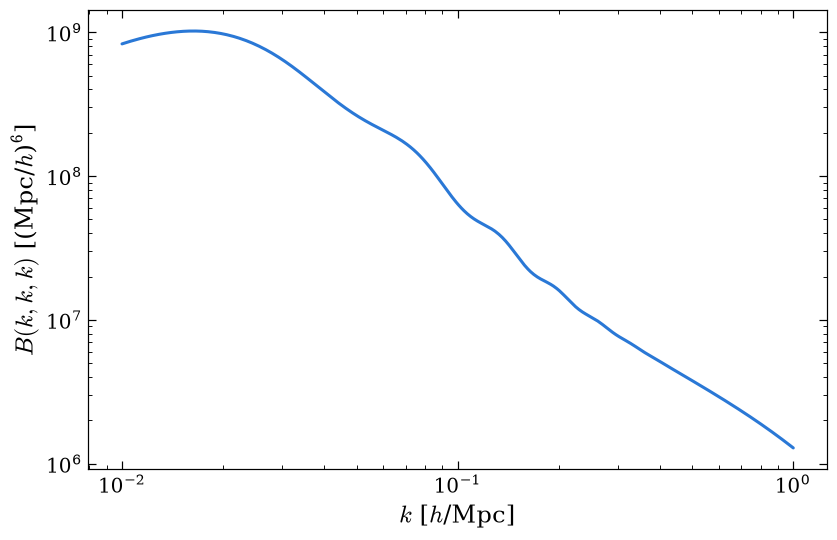

In [3]:
# Chosen cosmology used in this tutorial
omega_cold   = np.array([0.3089])     # Omega_cdm + Omega_b: already includes the baryons
omega_baryon = np.array([0.0486])
sigma8_cold  = np.array([0.8159])
ns           = np.array([0.9667])
hubble       = np.array([0.6774])

# Build cosmology object
cosmo = Cosmology(omega_cold, omega_baryon,
                  sigma8_cold, ns, hubble)

# Making the triangle set 
k_grid = np.logspace(-2, 0, 1000)    # 0.01 to 1.0 h/Mpc
k1_t, k2_t, k3_t = k_grid, k_grid, k_grid  # All combinations of k1, k2, k3

# Build bihalofit callable
bhf = make_bihalofit(k1_t, k2_t, k3_t, # triangles in h/Mpc
                     np.array([1.0]), # scale factor a=1 is redshift z=0
                     N_R=15, # Number of Newton iterations used to locate k_nl
                     R_min=1e-6, R_max=40.0, # Range of R values used to locate k_nl, 
                     term='full', # Tree, 1h, 3h or full (=B1h + B3h)
                     )

# Evaluate at the chosen cosmology 
B_arr = bhf(cosmo)[0, 0, :]  # Shape of output is (N_cosmo, N_z, N_tri) so here we fix Ncosmo and Nz                   

# Plotting
fig, ax = plt.subplots()
ax.plot(k1_t, B_arr)
ax.set_yscale('log')
ax.set_xscale('log')
ax.set_xlabel(r'$k$ [$h$/Mpc]')
ax.set_ylabel(r'$B(k,k,k)$ [(Mpc/$h$)$^6$]')
plt.show()

## 3. Multiple redshifts

Redshifts enter as scale factors $a=1/(1+z)$ when you build. One call covers all of them.

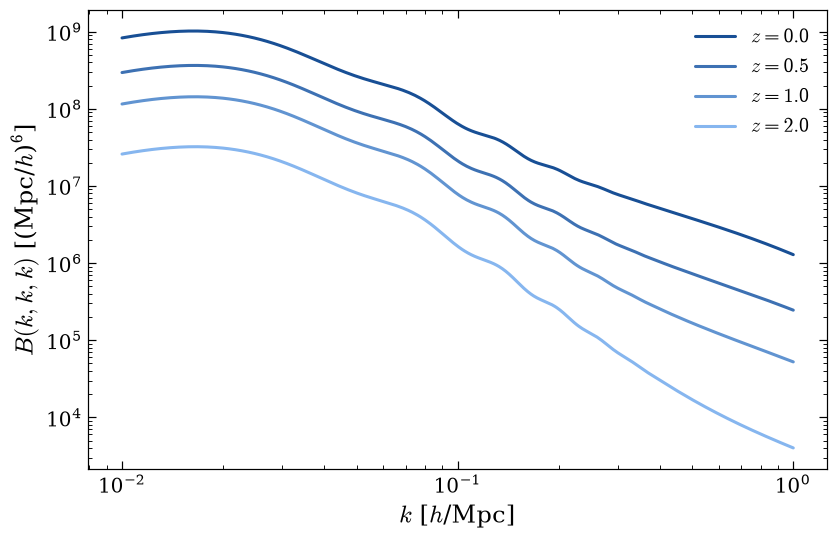

In [4]:
z_arr = np.array([0.0, 0.5, 1.0, 2.0])
a_arr = 1.0 / (1.0 + z_arr)                    # scale factors

# Equilateral bispectrum on a log-spaced k grid
k_grid = np.logspace(-2, 0, 1000)              # 0.01 to 1.0 h/Mpc

bhf_z = make_bihalofit(k_grid, k_grid, k_grid, a_arr)
B_z   = bhf_z(cosmo)                           # (N_cosmo, N_z, N_k) = (1, 4, 1000)

fig, ax = plt.subplots()
for iz, z in enumerate(z_arr):        # redshift is ordered, so a one-hue ramp: z=0 darkest
    ax.loglog(k_grid, np.asarray(B_z[0, iz, :]), color=BLUES(1 - iz / (len(z_arr) - 1)), label=rf'$z={z:.1f}$')
ax.set_xlabel(r'$k$ [$h$/Mpc]')
ax.set_ylabel(r'$B(k,k,k)$ [(Mpc/$h$)$^6$]')
ax.legend()
plt.show()

## 4. Multiple cosmologies

A `Cosmology` field is a scalar or a shape `(N_cosmo,)` array, so one call evaluates a whole batch.
Here: 100 cosmologies from a Latin hypercube, through the *same* `bhf_z` as above. Output shape
`(100, 4, N_k)`.

Output shape: (100, 4, 1000)


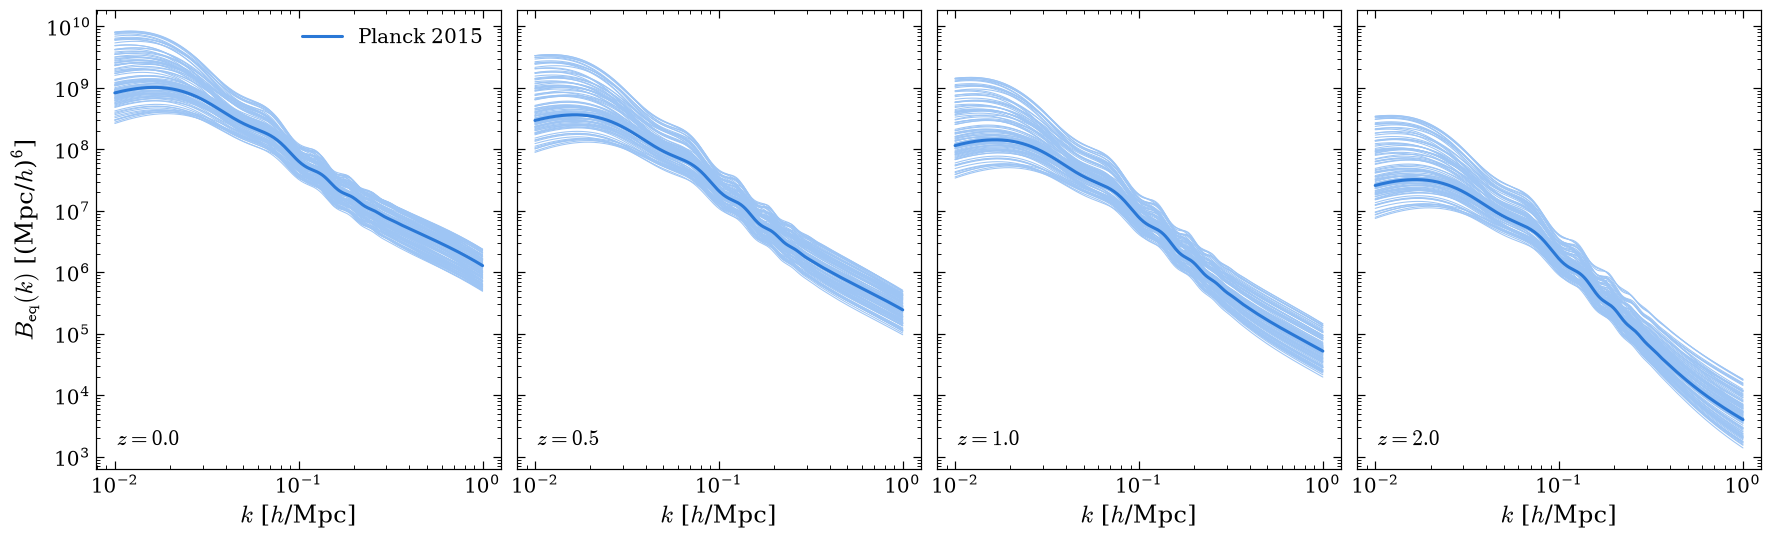

In [5]:
N_cosmo = 100

# Latin hypercube sample over [min, max] for each parameter (numpy only)
param_bounds = {
    'omega_cold':   (0.20, 0.35),
    'omega_baryon': (0.04, 0.06),
    'sigma8_cold':  (0.70, 0.90),
    'ns':           (0.92, 1.01),
    'hubble':       (0.60, 0.80),
}
rng    = np.random.default_rng(42)
n_p    = len(param_bounds)
cuts   = np.linspace(0, 1, N_cosmo + 1)
points = np.array([cuts[rng.permutation(N_cosmo)] + rng.uniform(size=N_cosmo) / N_cosmo
                   for _ in range(n_p)]).T
lows   = np.array([v[0] for v in param_bounds.values()])
highs  = np.array([v[1] for v in param_bounds.values()])
scaled = lows + points * (highs - lows)
oc, ob, s8, n_s, h = scaled.T

# Every field is a shape (N_cosmo,) array, so one call covers all 100 cosmologies.
cosmo_lhc = Cosmology(omega_cold=oc, omega_baryon=ob,
                      sigma8_cold=s8, ns=n_s, hubble=h)

B_multi = bhf_z(cosmo_lhc)
print(f'Output shape: {B_multi.shape}')   # (100, 4, 1000)

fig, axes = plt.subplots(1, 4, figsize=(16, 4.8), sharey=True)
for iz, (ax, z) in enumerate(zip(axes, z_arr)):
    for ic in range(N_cosmo):
        ax.loglog(k_grid, np.array(B_multi[ic, iz, :]), lw=0.7, color='#9ec5f4')     # the band of 100 cosmologies
    ax.loglog(k_grid, np.asarray(B_z[0, iz, :]), label='Planck 2015' if iz == 0 else None)   # the fiducial one
    ax.text(0.05, 0.05, rf'$z={z:.1f}$', transform=ax.transAxes)
    ax.set_xlabel(r'$k$ [$h$/Mpc]')
axes[0].set_ylabel(r'$B_\mathrm{eq}(k)$ [(Mpc/$h$)$^6$]')
axes[0].legend()
plt.show()

## 5. Linear power spectrum backend

`pk_source` picks the linear P(k): `'syren'` (default, symbolic fit with wCDM and neutrinos), `'eh'` and `'eh_99'`
(Eisenstein & Hu fitting formulae), all in JAX with no extra dependency, and `'baccoemu'` (neural-network
emulator, needs `pip install "bihalofit-jax[baccoemu]"`). Below, `'eh'` and `'baccoemu'` against the default.

Loading sigma8 emulator...
Sigma8 emulator loaded in memory.
Loading linear emulator...
Linear emulator loaded in memory.
Loading no-wiggles emulator...
No-wiggles emulator loaded in memory.
Loading non-linear emulator...
Nonlinear emulator loaded in memory.
Loading Baryonic Emulator Arico et al. (2021)...
Baryonic Emulator Arico et al. (2025) loaded in memory.


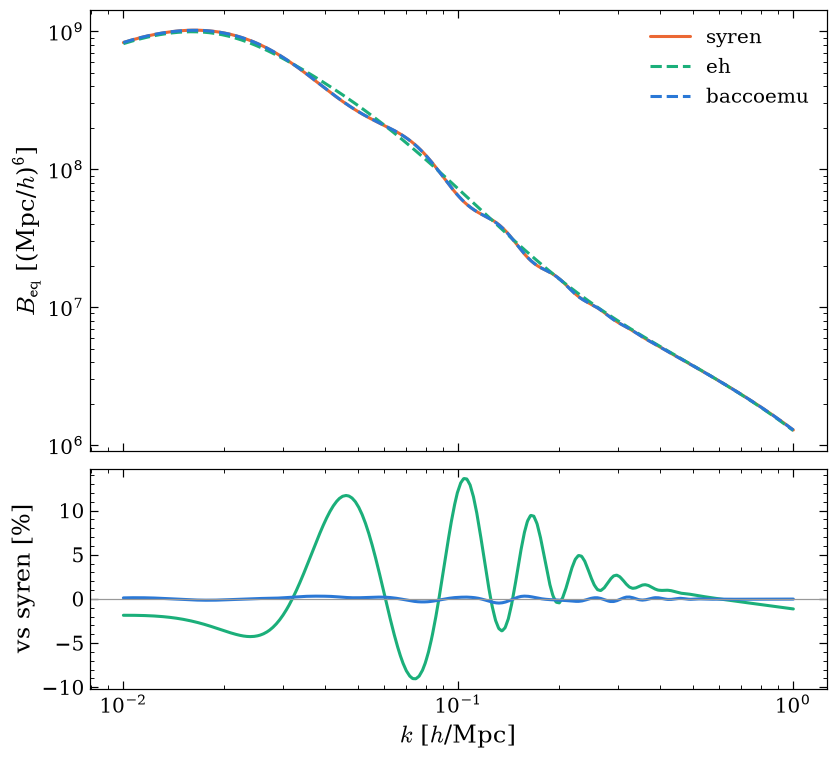

In [6]:
a0 = np.array([1.0])  # a = 1, i.e. z = 0

B_eh    = make_bihalofit(k_grid, k_grid, k_grid, a0, pk_source='eh')(cosmo)[0,0,:] # [0,0,:] to select first cosmology and first redshift
B_bacco = make_bihalofit(k_grid, k_grid, k_grid, a0, pk_source='baccoemu')(cosmo)[0,0,:]

# Compare to the syren (default) result B_z from section 3
ratio_eh    = np.array(B_eh) / np.array(B_z[0,0,:])
ratio_bacco = np.array(B_bacco) / np.array(B_z[0,0,:])

fig, axes = plt.subplots(2, 1, figsize=(7.5, 6.8), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
axes[0].loglog(k_grid, np.array(B_z[0, 0, :]), color=COLOUR['syren'], label='syren')
axes[0].loglog(k_grid, np.array(B_eh), color=COLOUR['eh'], ls='--', label='eh')
axes[0].loglog(k_grid, np.array(B_bacco), color=COLOUR['baccoemu'], ls='--', label='baccoemu')
axes[0].set_ylabel(r'$B_\mathrm{eq}$ [(Mpc/$h$)$^6$]')
axes[0].legend()
axes[1].semilogx(k_grid, 100 * (ratio_eh - 1), color=COLOUR['eh'], label='eh')
axes[1].semilogx(k_grid, 100 * (ratio_bacco - 1), color=COLOUR['baccoemu'], label='baccoemu')
axes[1].axhline(0, color='0.6', lw=0.8)
axes[1].set_xlabel(r'$k$ [$h$/Mpc]')
axes[1].set_ylabel('vs syren [%]')
plt.show()

## 6. Derivatives with JAX

`bhf` is a pure JAX function, so JAX's transformations apply to it directly. `jax.jacfwd(bhf)(cosmo)`
returns the derivative of every output with respect to every parameter. Because `Cosmology` is a
pytree, the result is another `Cosmology` whose fields hold the derivatives: `jac.omega_baryon` is
$\partial B/\partial\Omega_{\rm b}$.

**Important**: each `jax.jacfwd` field has shape `(N_cosmo, N_z, N_k, N_cosmo)`. Only the diagonal in the two
cosmology axes (`[i, :, :, i]`) is non-zero.

Below is the response of the equilateral bispectrum to $\Omega_{\rm b}$,
$d\ln B/d\ln\Omega_{\rm b}=(\partial B/\partial\Omega_{\rm b})\,\Omega_{\rm b}/B$: the percentage
change in $B$ for a 1% change in $\Omega_{\rm b}$, with the other parameters held fixed.

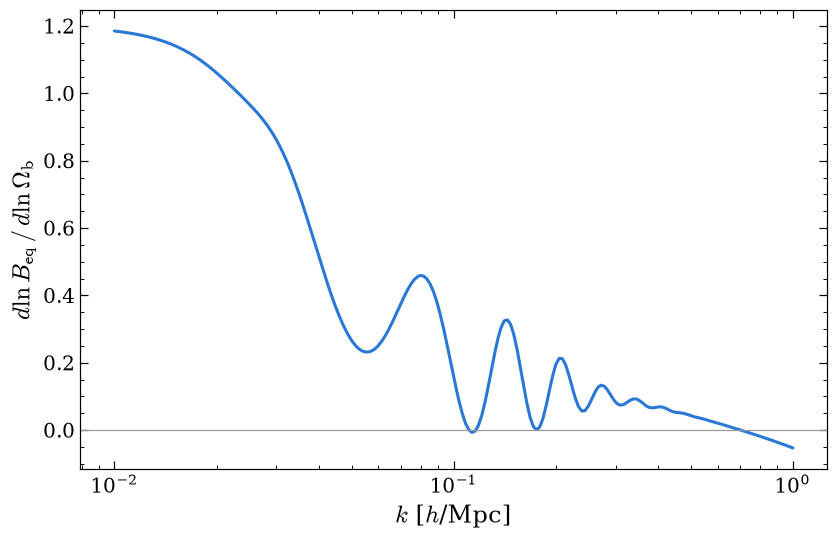

In [7]:
# Build bihalofit for equilaterals at z=0 
bhf = make_bihalofit(k_grid, k_grid, k_grid, np.array([1.0]))    
# Evaluate at the chosen cosmology
B   = bhf(cosmo)   # Shape is (N_cosmo, N_z, N_k) = (1, 1, 1000)                            

# Evaluating the Jacobian at a given cosmology
jac = jax.jacfwd(bhf)(cosmo)   # Shape is (N_cosmo , N_z, N_k, N_cosmo) = (1, 1, 1000, 1)

# Logarithmic derivative with respect to Omega_baryon
dlnB_dlnOmega = jac.omega_baryon[0, 0, :, 0] / B[0, 0, :] * cosmo.omega_baryon[0]

fig, ax = plt.subplots()
ax.semilogx(k_grid, dlnB_dlnOmega)
ax.axhline(0, color='0.6', lw=0.8)
ax.set_xlabel(r'$k$ [$h$/Mpc]')
ax.set_ylabel(r'$d\ln B_{\rm eq}\,/\,d\ln\Omega_{\rm b }$')
plt.show()